to check the one cavity file

In [1]:
import torch


In [ ]:
import torch

data = torch.load("filtered_data_tensor-MBL-090RFC__RFS-EVR-101.pt", map_location="cpu", weights_only=True)

In [2]:
print(torch.__version__)

2.10.0a0+a36e1d39eb.nv26.01.42222806


In [8]:
print(type(data))
print(data)

<class 'torch.Tensor'>
tensor([[[ 3.2307e-02,  3.0404e-02,  3.0747e-02,  ...,  4.3417e-02,
           4.2127e-02,  4.2768e-02],
         [-6.9941e-03,  1.8429e+01,  1.4030e+01,  ..., -7.1571e+01,
          -6.8200e+01, -6.8969e+01],
         [-4.3899e-01, -4.3898e-01, -4.3900e-01,  ..., -4.3900e-01,
          -4.3882e-01, -4.3899e-01],
         [-1.2369e+02,  4.4993e+01,  1.8429e+01,  ...,  5.9030e+01,
           3.6027e+01,  5.6303e+01],
         [-4.3602e-01, -4.3602e-01, -4.3601e-01,  ..., -4.3560e-01,
          -4.3457e-01, -4.3538e-01],
         [-6.9941e-03, -2.6571e+01, -3.3691e+01,  ...,  2.3626e+01,
           2.2927e+01,  8.5258e+00]],

        [[ 3.2741e-02,  3.0404e-02,  3.1109e-02,  ...,  4.1494e-02,
           4.0868e-02,  4.1494e-02],
         [-1.2533e+01,  1.8429e+01,  3.6866e+01,  ..., -7.1571e+01,
          -7.0822e+01, -7.3746e+01],
         [-4.3893e-01, -4.3899e-01, -4.3882e-01,  ..., -4.3898e-01,
          -4.3900e-01, -4.3893e-01],
         [ 8.4286e+01,  3.9804

[Number of event, 6, number of points in waveforms]

In [9]:
print(data.shape)

torch.Size([311, 6, 35221])


In [29]:
import torch
import torch.nn as nn

class RFAutoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv1d(6, 12, kernel_size=8, stride=4, padding=2),
            nn.GELU(),
            nn.Conv1d(12, 24, kernel_size=8, stride=4, padding=2),
            nn.GELU(),
            nn.Flatten(),
            nn.Linear(52824, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 52824),
            nn.Unflatten(1, (24, 2201)),
            nn.ConvTranspose1d(
                24, 12, kernel_size=8,
                stride=4, padding=2, output_padding=1
            ),
            nn.GELU(),
            nn.ConvTranspose1d(
                12, 6, kernel_size=8,
                stride=4, padding=2, output_padding=1
            )
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed

In [30]:
x = batch.to(device)

for layer in model.encoder:
    if isinstance(layer, nn.Linear):
        print("Linear直前:", x.shape)
        print("Linearが期待するサイズ:", layer.in_features)
        break

    x = layer(x)

Linear直前: torch.Size([4, 52824])
Linearが期待するサイズ: 52824


In [31]:
# 読み込み済みのTensor
X = data.float()

# チャンネルごとに標準化
mean = X.mean(dim=(0, 2), keepdim=True)
std = X.std(dim=(0, 2), keepdim=True).clamp_min(1e-8)

X = (X - mean) / std

print(X.shape)

torch.Size([311, 6, 35221])


In [32]:
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = RFAutoencoder(latent_dim=2).to(device)

loader = DataLoader(
    TensorDataset(X),
    batch_size=4,
    shuffle=True
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(20):
    model.train()
    total_loss = 0

    for (batch,) in loader:
        batch = batch.to(device)

        output = model(batch)
        loss = F.mse_loss(output, batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}: Loss = {total_loss/len(loader):.6f}")

Epoch 1: Loss = 0.906979
Epoch 2: Loss = 0.478732
Epoch 3: Loss = 0.230802
Epoch 4: Loss = 0.251655
Epoch 5: Loss = 0.209956
Epoch 6: Loss = 0.718554
Epoch 7: Loss = 0.194699
Epoch 8: Loss = 0.171231
Epoch 9: Loss = 0.161835
Epoch 10: Loss = 0.154639
Epoch 11: Loss = 0.148096
Epoch 12: Loss = 0.142288
Epoch 13: Loss = 0.134793
Epoch 14: Loss = 0.127040
Epoch 15: Loss = 0.117548
Epoch 16: Loss = 0.109671
Epoch 17: Loss = 0.103737
Epoch 18: Loss = 0.099600
Epoch 19: Loss = 0.096895
Epoch 20: Loss = 0.094856


In [36]:
model.eval()

eval_loader = DataLoader(
    TensorDataset(X),
    batch_size=4,
    shuffle=False
)

with torch.no_grad():
    Z = torch.cat([
        model.encoder(batch.to(device)).cpu()
        for (batch,) in eval_loader
    ])

print(Z.shape)

torch.Size([311, 2])


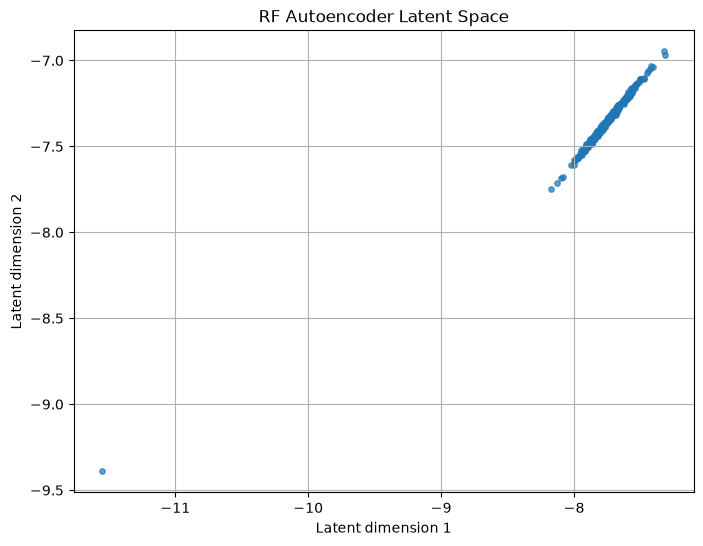

In [37]:
import matplotlib.pyplot as plt

Z = Z.numpy()

plt.figure(figsize=(8, 6))
plt.scatter(Z[:, 0], Z[:, 1], s=15, alpha=0.7)

plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("RF Autoencoder Latent Space")
plt.grid(True)
plt.show()

In [49]:
device = next(model.parameters()).device

loader = DataLoader(data, batch_size=8, shuffle=False)

errors = []

with torch.no_grad():
    for x in loader:
        x = x.to(device).float()

        reconstructed = model(x)

        # イベントごとの再構成誤差
        error = ((x - reconstructed) ** 2).mean(dim=(1, 2))

        errors.append(error.cpu())

errors = torch.cat(errors).numpy()

print(errors.shape)  # (311,)

(311,)


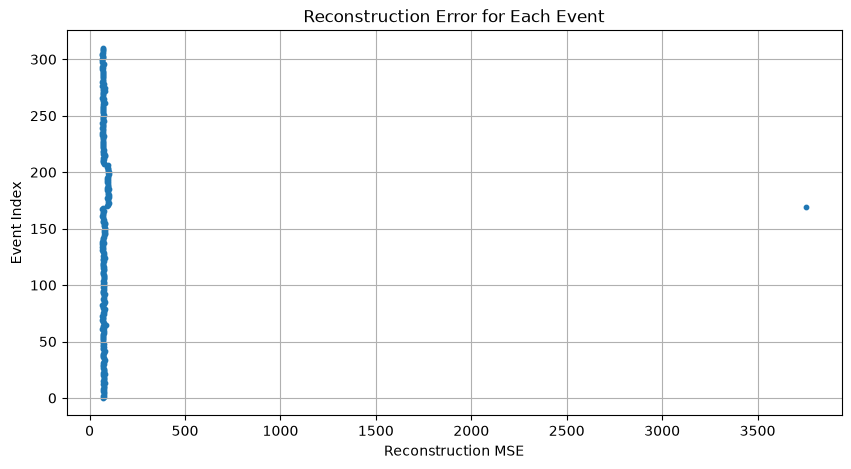

In [54]:
import numpy as np

plt.figure(figsize=(10, 5))
plt.scatter(errors, np.arange(len(errors)), s=10)

plt.xlabel("Reconstruction MSE")
plt.ylabel("Event Index")
plt.title("Reconstruction Error for Each Event")
plt.grid(True)

plt.show()

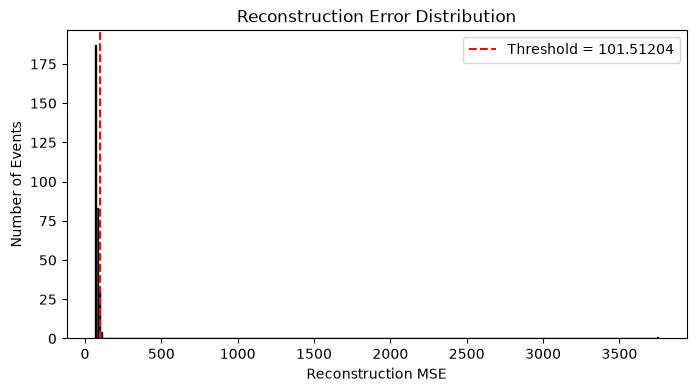

In [69]:
threshold = np.percentile(errors, 99)

plt.figure(figsize=(8, 4))

plt.hist(errors, bins=400, edgecolor="black")

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label=f"Threshold = {threshold:.5f}"
)

plt.xlabel("Reconstruction MSE")
plt.ylabel("Number of Events")
plt.title("Reconstruction Error Distribution")
plt.legend()
plt.show()

In [70]:
anomalies = np.where(errors > threshold)[0]

print("Anomaly candidates:", anomalies)
print("Number of candidates:", len(anomalies))

Anomaly candidates: [169 185 198 200]
Number of candidates: 4


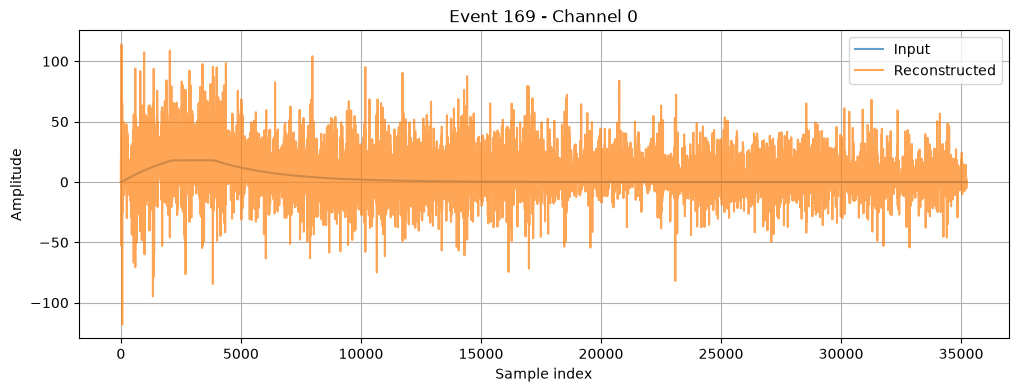

In [66]:
# 最も誤差が大きいイベント
idx = np.argmax(errors)

with torch.no_grad():
    x = data[idx:idx+1].to(device).float()
    reconstructed = model(x)

# チャンネル0を取り出す
original = x[0, 0].cpu().numpy()
recon = reconstructed[0, 0].cpu().numpy()

# 描画
plt.figure(figsize=(12, 4))

plt.plot(original, label="Input", alpha=0.7)
plt.plot(recon, label="Reconstructed", alpha=0.7)

plt.xlabel("Sample index")
plt.ylabel("Amplitude")
plt.title(f"Event {idx} - Channel 0")
plt.legend()
plt.grid(True)

plt.show()

In [71]:
# 除外するイベント番号
exclude_indices = [169]

# 学習用データを作る
mask = torch.ones(len(data), dtype=torch.bool, device=data.device)
mask[exclude_indices] = False

train_data = data[mask]

print(train_data.shape)
# torch.Size([308, 6, 35221])

torch.Size([310, 6, 35221])


In [72]:
# 再構成誤差が大きい上位10イベント
indices = np.argsort(errors)[-10:][::-1]

for idx in indices:
    print(f"Event {idx}: MSE = {errors[idx]:.6f}")

Event 169: MSE = 3755.758545
Event 185: MSE = 103.757660
Event 200: MSE = 101.748009
Event 198: MSE = 101.548691
Event 180: MSE = 101.182167
Event 178: MSE = 99.855568
Event 173: MSE = 99.180489
Event 197: MSE = 99.029434
Event 179: MSE = 98.893036
Event 199: MSE = 98.479897
